<a href="https://colab.research.google.com/github/AnirudhRajesh09/BIS/blob/main/BIS_Pgm2_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

       NEURAL NETWORK TRAINING RESULTS
Network architecture : 2 - 4 - 1
PSO iterations       : 640
PSO final MSE        : 0.00099837
PSO runtime          : 0.954 seconds
-------------------------------------------------------
BP epochs            : 5339
BP final MSE         : 0.00099963
BP runtime           : 0.505 seconds
-------------------------------------------------------
Required error goal  : 0.001
PSO reached goal     : True
BP reached goal      : True


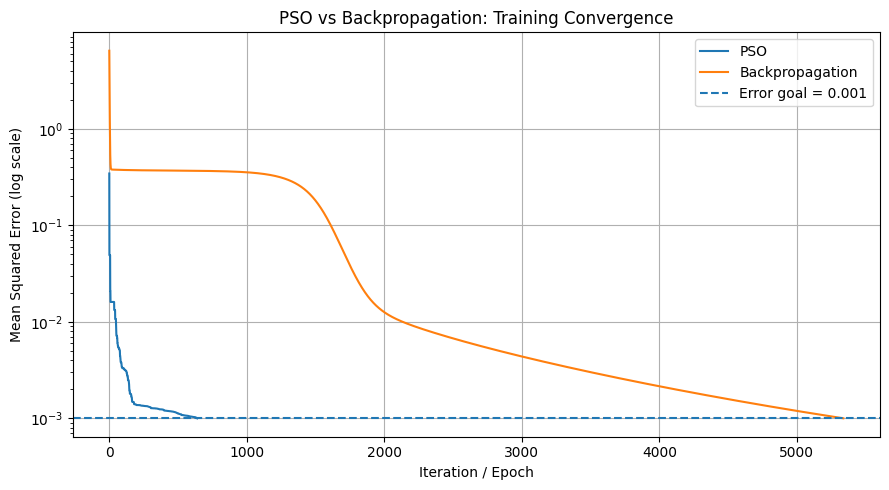

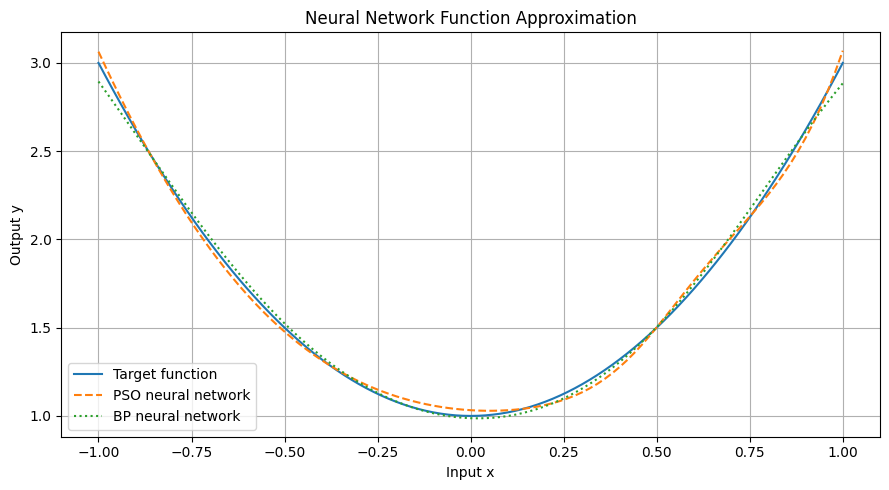

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
import time

# ============================================================
# PSO-BASED NEURAL NETWORK TRAINING
# Based on Gudise & Venayagamoorthy, IEEE SIS 2003
#
# Architecture: input x + bias input (1) -> 4 sigmoid
# hidden neurons -> 1 linear output neuron
#
# Comparison: Particle Swarm Optimization vs Backpropagation
# ============================================================

np.random.seed(42)

# -------------------- 1. DATASET ----------------------------

# Paper-informed target function; verify against the original PDF.
x = np.linspace(-1, 1, 101).reshape(-1, 1)
y = 2 * x**2 + 1

# Second input is a constant bias input.
X = np.hstack([x, np.ones_like(x)])

N = len(X)
HIDDEN = 4
DIM = 2 * HIDDEN + HIDDEN  # 8 input-hidden + 4 hidden-output weights
ERROR_GOAL = 0.001

# -------------------- 2. NEURAL NETWORK ---------------------

def sigmoid(z):
    z = np.clip(z, -50, 50)
    return 1 / (1 + np.exp(-z))


def unpack(p):
    W1 = p[:8].reshape(2, 4)
    W2 = p[8:12].reshape(4, 1)
    return W1, W2


def forward(p, inputs):
    W1, W2 = unpack(p)
    hidden = sigmoid(inputs @ W1)
    output = hidden @ W2  # Linear output
    return output


def mse(p):
    return np.mean((forward(p, X) - y) ** 2)


# -------------------- 3. PSO TRAINING -----------------------

def train_pso():
    particles = 40
    iterations = 2000

    w = 0.729
    c1 = 1.49445
    c2 = 1.49445

    lower, upper = -10.0, 10.0

    pos = np.random.uniform(
        lower, upper, (particles, DIM)
    )
    vel = np.random.uniform(
        -1, 1, (particles, DIM)
    )

    def swarm_fitness(population):
        W1 = population[:, :8].reshape(-1, 2, 4)
        W2 = population[:, 8:12].reshape(-1, 4, 1)

        hidden = sigmoid(np.einsum("ni,pih->pnh", X, W1))
        output = np.einsum("pnh,phk->pnk", hidden, W2)
        return np.mean((output - y[None, :, :])**2, axis=(1, 2))

    scores = swarm_fitness(pos)
    pbest = pos.copy()
    pbest_scores = scores.copy()

    idx = np.argmin(scores)
    gbest = pos[idx].copy()
    gbest_score = scores[idx]

    history = []

    for it in range(iterations):
        r1 = np.random.rand(particles, DIM)
        r2 = np.random.rand(particles, DIM)

        vel = (
            w * vel
            + c1 * r1 * (pbest - pos)
            + c2 * r2 * (gbest - pos)
        )

        pos = np.clip(pos + vel, lower, upper)
        scores = swarm_fitness(pos)

        improved = scores < pbest_scores
        pbest[improved] = pos[improved]
        pbest_scores[improved] = scores[improved]

        idx = np.argmin(pbest_scores)
        if pbest_scores[idx] < gbest_score:
            gbest_score = pbest_scores[idx]
            gbest = pbest[idx].copy()

        history.append(gbest_score)

        if gbest_score <= ERROR_GOAL:
            break

    return gbest, history, it + 1


# -------------------- 4. BACKPROPAGATION --------------------

def train_bp():
    # Random initialization; full-batch gradient descent.
    W1 = np.random.uniform(-1, 1, (2, 4))
    W2 = np.random.uniform(-1, 1, (4, 1))

    learning_rate = 0.1
    max_epochs = 20000
    history = []

    for epoch in range(max_epochs):
        hidden = sigmoid(X @ W1)
        output = hidden @ W2
        error = output - y

        loss = np.mean(error**2)
        history.append(loss)

        if loss <= ERROR_GOAL:
            break

        # Gradient of mean squared error
        dW2 = (2 / N) * hidden.T @ error
        delta_hidden = (error @ W2.T) * hidden * (1 - hidden)
        dW1 = (2 / N) * X.T @ delta_hidden

        W2 -= learning_rate * dW2
        W1 -= learning_rate * dW1

    weights = np.concatenate([W1.flatten(), W2.flatten()])
    return weights, history, epoch + 1


# -------------------- 5. RUN BOTH METHODS -------------------

start = time.perf_counter()
pso_weights, pso_history, pso_steps = train_pso()
pso_time = time.perf_counter() - start

start = time.perf_counter()
bp_weights, bp_history, bp_steps = train_bp()
bp_time = time.perf_counter() - start

pso_predictions = forward(pso_weights, X)
bp_predictions = forward(bp_weights, X)

pso_mse = np.mean((pso_predictions - y)**2)
bp_mse = np.mean((bp_predictions - y)**2)

print("=" * 55)
print("       NEURAL NETWORK TRAINING RESULTS")
print("=" * 55)
print(f"Network architecture : 2 - 4 - 1")
print(f"PSO iterations       : {pso_steps}")
print(f"PSO final MSE        : {pso_mse:.8f}")
print(f"PSO runtime          : {pso_time:.3f} seconds")
print("-" * 55)
print(f"BP epochs            : {bp_steps}")
print(f"BP final MSE         : {bp_mse:.8f}")
print(f"BP runtime           : {bp_time:.3f} seconds")
print("-" * 55)
print(f"Required error goal  : {ERROR_GOAL}")
print(f"PSO reached goal     : {pso_mse <= ERROR_GOAL}")
print(f"BP reached goal      : {bp_mse <= ERROR_GOAL}")
print("=" * 55)

# -------------------- 6. CONVERGENCE GRAPH ------------------

plt.figure(figsize=(9, 5))
plt.semilogy(
    np.maximum(pso_history, 1e-12),
    label="PSO"
)
plt.semilogy(
    np.maximum(bp_history, 1e-12),
    label="Backpropagation"
)
plt.axhline(
    ERROR_GOAL, linestyle="--",
    label="Error goal = 0.001"
)
plt.xlabel("Iteration / Epoch")
plt.ylabel("Mean Squared Error (log scale)")
plt.title("PSO vs Backpropagation: Training Convergence")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# -------------------- 7. FUNCTION APPROXIMATION --------------

plt.figure(figsize=(9, 5))
plt.plot(x, y, label="Target function")
plt.plot(x, pso_predictions, "--", label="PSO neural network")
plt.plot(x, bp_predictions, ":", label="BP neural network")
plt.xlabel("Input x")
plt.ylabel("Output y")
plt.title("Neural Network Function Approximation")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


Iteration  20 | Iteration best = 306.56 | Best-so-far = 306.56
Iteration  40 | Iteration best = 306.56 | Best-so-far = 306.56
Iteration  60 | Iteration best = 306.56 | Best-so-far = 306.56
Iteration  80 | Iteration best = 306.56 | Best-so-far = 306.56
Iteration 100 | Iteration best = 306.56 | Best-so-far = 306.56
Iteration 120 | Iteration best = 306.56 | Best-so-far = 306.56
Iteration 140 | Iteration best = 306.56 | Best-so-far = 306.56
Iteration 160 | Iteration best = 306.56 | Best-so-far = 306.56
Iteration 180 | Iteration best = 306.56 | Best-so-far = 306.56
Iteration 200 | Iteration best = 306.56 | Best-so-far = 306.56

========== ACS TSP RESULTS ==========
Number of cities: 10
Number of ants: 10
Iterations: 200
Nearest-neighbour initial tour length: 351.19
Best route (city numbers): [6, 4, 1, 3, 2, 5, 7, 10, 8, 9, 6]
Best tour length: 306.56


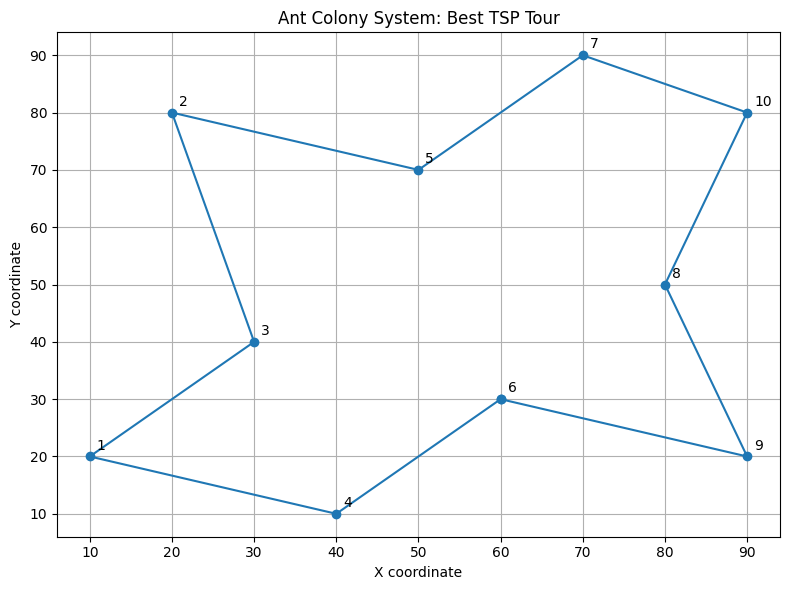

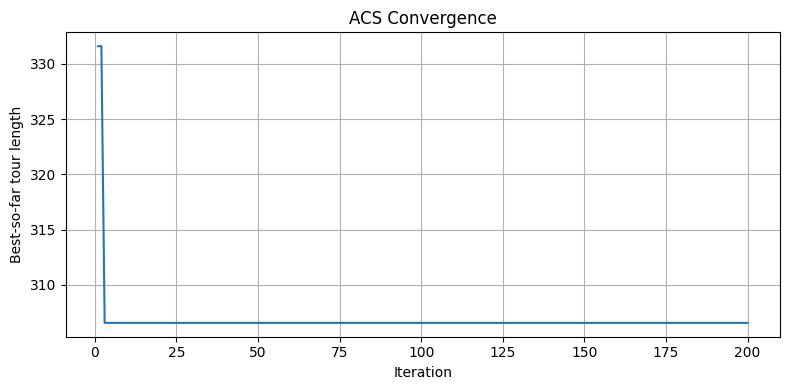

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# ANT COLONY SYSTEM (ACS) FOR THE TRAVELLING SALESMAN PROBLEM
#
# Based on:
# M. Dorigo and L. M. Gambardella, IEEE TEC, 1997
# DOI: 10.1109/4235.585892
#
# Implements core ACS, without the optional 3-opt extension.
# ============================================================

np.random.seed(42)

# 1. Define the cities (x, y coordinates)
cities = np.array([
    [10, 20],
    [20, 80],
    [30, 40],
    [40, 10],
    [50, 70],
    [60, 30],
    [70, 90],
    [80, 50],
    [90, 20],
    [90, 80]
], dtype=float)

N = len(cities)

# 2. Calculate the symmetric distance matrix
distance = np.linalg.norm(
    cities[:, np.newaxis, :] - cities[np.newaxis, :, :],
    axis=2
)

# Heuristic desirability: shorter edges are preferred
visibility = np.zeros_like(distance)
mask = distance > 0
visibility[mask] = 1.0 / distance[mask]

# 3. ACS parameters
NUM_ANTS = N
ITERATIONS = 200

BETA = 2.0       # Importance of distance heuristic
Q0 = 0.9         # Probability of greedy exploitation
RHO = 0.1        # Local pheromone update coefficient
ALPHA = 0.1      # Global pheromone update coefficient

# 4. Initialize pheromone using a nearest-neighbour tour length
def nearest_neighbor_length(start=0):
    unvisited = set(range(N))
    unvisited.remove(start)
    current = start
    total = 0.0

    while unvisited:
        next_city = min(
            unvisited,
            key=lambda city: distance[current, city]
        )
        total += distance[current, next_city]
        unvisited.remove(next_city)
        current = next_city

    total += distance[current, start]
    return total


L_nn = nearest_neighbor_length()
tau0 = 1.0 / (N * L_nn)

pheromone = np.full((N, N), tau0)
np.fill_diagonal(pheromone, 0.0)

best_route = None
best_length = float("inf")
history = []

# 5. Main ACS iterations
for iteration in range(ITERATIONS):

    iteration_best_route = None
    iteration_best_length = float("inf")

    # Each ant constructs a complete tour
    for ant in range(NUM_ANTS):

        start = np.random.randint(N)
        route = [start]
        unvisited = set(range(N))
        unvisited.remove(start)

        # Construct the tour city by city
        while unvisited:
            current = route[-1]
            candidates = np.array(sorted(unvisited), dtype=int)

            # ACS transition rule:
            # desirability = pheromone * (1 / distance)^beta
            desirability = (
                pheromone[current, candidates]
                * visibility[current, candidates] ** BETA
            )

            # q <= q0: exploit the best edge
            # otherwise: probabilistically explore
            if np.random.random() <= Q0:
                next_city = candidates[np.argmax(desirability)]
            else:
                probabilities = desirability / desirability.sum()
                next_city = np.random.choice(
                    candidates, p=probabilities
                )

            route.append(int(next_city))
            unvisited.remove(int(next_city))

            # Local pheromone update immediately after using an edge
            pheromone[current, next_city] = (
                (1 - RHO) * pheromone[current, next_city]
                + RHO * tau0
            )
            pheromone[next_city, current] = (
                pheromone[current, next_city]
            )

        # Return to the starting city and locally update that edge
        route.append(start)
        current = route[-2]

        pheromone[current, start] = (
            (1 - RHO) * pheromone[current, start]
            + RHO * tau0
        )
        pheromone[start, current] = pheromone[current, start]

        # Calculate total tour length
        length = sum(
            distance[route[i], route[i + 1]]
            for i in range(N)
        )

        if length < iteration_best_length:
            iteration_best_length = length
            iteration_best_route = route.copy()

        if length < best_length:
            best_length = length
            best_route = route.copy()

    # 6. Global pheromone update on the best-so-far tour
    # Edges not belonging to this tour are left unchanged.
    for i in range(N):
        a = best_route[i]
        b = best_route[i + 1]

        updated = (
            (1 - ALPHA) * pheromone[a, b]
            + ALPHA / best_length
        )

        pheromone[a, b] = updated
        pheromone[b, a] = updated

    history.append(best_length)

    if (iteration + 1) % 20 == 0:
        print(
            f"Iteration {iteration + 1:3d} | "
            f"Iteration best = {iteration_best_length:.2f} | "
            f"Best-so-far = {best_length:.2f}"
        )

# 7. Print the final results
print("\n========== ACS TSP RESULTS ==========")
print("Number of cities:", N)
print("Number of ants:", NUM_ANTS)
print("Iterations:", ITERATIONS)
print("Nearest-neighbour initial tour length:", round(L_nn, 2))
print("Best route (city numbers):",
      [city + 1 for city in best_route])
print("Best tour length:", round(best_length, 2))
print("=====================================")

# 8. Visualize the best tour
route_coordinates = cities[best_route]

plt.figure(figsize=(8, 6))
plt.plot(
    route_coordinates[:, 0],
    route_coordinates[:, 1],
    "o-"
)

for i, (x, y) in enumerate(cities):
    plt.annotate(
        str(i + 1),
        (x, y),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.title("Ant Colony System: Best TSP Tour")
plt.xlabel("X coordinate")
plt.ylabel("Y coordinate")
plt.grid(True)
plt.tight_layout()
plt.show()

# 9. Visualize convergence
plt.figure(figsize=(8, 4))
plt.plot(
    range(1, ITERATIONS + 1),
    history
)
plt.title("ACS Convergence")
plt.xlabel("Iteration")
plt.ylabel("Best-so-far tour length")
plt.grid(True)
plt.tight_layout()
plt.show()
